In [1]:
!pip -q install gdown

!gdown --fuzzy \
"https://drive.google.com/file/d/1PxuNRcCHmedctrmYi14pVRc02rGoUXHD/view?usp=sharing" \
-O /content/humanli_dataset

!ls -lh /content/humanli_dataset
!file /content/humanli_dataset

Downloading...
From (original): https://drive.google.com/uc?id=1PxuNRcCHmedctrmYi14pVRc02rGoUXHD
From (redirected): https://drive.google.com/uc?id=1PxuNRcCHmedctrmYi14pVRc02rGoUXHD&confirm=t&uuid=c4f3493d-a5e7-4182-a1c9-a33e124f17e1
To: /content/humanli_dataset
100% 730M/730M [00:10<00:00, 66.6MB/s]
-rw-r--r-- 1 root root 696M Nov  3 08:05 /content/humanli_dataset
/content/humanli_dataset: Zip archive data, at least v4.5 to extract, compression method=deflate


In [2]:
import zipfile
import os

ZIP_PATH = "/content/humanli_dataset"
EXTRACT_DIR = "/content/humanli_data"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    print("Files in archive:", len(zip_ref.namelist()))
    zip_ref.extractall(EXTRACT_DIR)

print("Extraction completed!")
print("Top-level contents:", os.listdir(EXTRACT_DIR)[:30])

Files in archive: 16130
Extraction completed!
Top-level contents: ['afhq']


In [3]:
from pathlib import Path
from collections import Counter
from PIL import Image
import os

DATA_DIR = Path("/content/humanli_data")

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

image_files = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

print("TOTAL IMAGES:", len(image_files))

# Image formats
formats = Counter(p.suffix.lower() for p in image_files)
print("\nIMAGE FORMATS:")
for ext, count in formats.items():
    print(ext, count)

# Directory structure
print("\nDIRECTORY STRUCTURE:")
for root, dirs, files in os.walk(DATA_DIR):
    level = len(Path(root).relative_to(DATA_DIR).parts)
    if level <= 3:
        print("  " * level + Path(root).name + "/")
        for f in files[:5]:
            print("  " * (level + 1) + f)

# Count images by immediate parent directory
class_counts = Counter(p.parent.name for p in image_files)

print("\nIMAGE COUNTS BY PARENT DIRECTORY:")
for name, count in class_counts.most_common():
    print(f"{name}: {count}")

# Inspect sample images
print("\nSAMPLE IMAGE INSPECTION:")
for path in image_files[:10]:
    try:
        with Image.open(path) as img:
            print(path.name, img.size, img.mode)
    except Exception as e:
        print("Unreadable:", path, str(e))

# Check for corrupt images
corrupt = []

for path in image_files:
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception:
        corrupt.append(str(path))

print("\nCORRUPT IMAGES:", len(corrupt))

TOTAL IMAGES: 16130

IMAGE FORMATS:
.jpg 16130

DIRECTORY STRUCTURE:
humanli_data/
  afhq/
    train/
      wild/
        flickr_wild_000362.jpg
        pixabay_wild_000608.jpg
        flickr_wild_001933.jpg
        flickr_wild_001082.jpg
        flickr_wild_001360.jpg
      dog/
        pixabay_dog_003837.jpg
        pixabay_dog_003428.jpg
        pixabay_dog_001103.jpg
        pixabay_dog_002131.jpg
        flickr_dog_000636.jpg
      cat/
        pixabay_cat_000234.jpg
        pixabay_cat_001391.jpg
        pixabay_cat_002540.jpg
        pixabay_cat_003257.jpg
        pixabay_cat_002802.jpg
    val/
      wild/
        flickr_wild_000147.jpg
        flickr_wild_000360.jpg
        pixabay_wild_000025.jpg
        flickr_wild_001219.jpg
        flickr_wild_003331.jpg
      dog/
        pixabay_dog_000351.jpg
        pixabay_dog_001800.jpg
        pixabay_dog_003709.jpg
        pixabay_dog_003351.jpg
        pixabay_dog_003914.jpg
      cat/
        pixabay_cat_002310.jpg
        pixaba

In [4]:
from pathlib import Path

ROOT = Path("/content/humanli_data/afhq")

print("DATASET ROOT:", ROOT)
print("\nFOLDER STRUCTURE:")

for path in sorted(ROOT.rglob("*")):
    if path.is_dir():
        print("DIR :", path.relative_to(ROOT))
    elif path.is_file():
        print("FILE:", path.relative_to(ROOT))

    if len(list(ROOT.rglob("*"))) > 100:
        break

DATASET ROOT: /content/humanli_data/afhq

FOLDER STRUCTURE:
DIR : train


In [5]:
from collections import Counter
from pathlib import Path

ROOT = Path("/content/humanli_data/afhq")

for split in ["train", "val", "test"]:
    split_dir = ROOT / split

    if not split_dir.exists():
        continue

    print(f"\n{split.upper()}")

    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            count = sum(
                1 for p in class_dir.iterdir()
                if p.suffix.lower() in {
                    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
                }
            )
            print(f"{class_dir.name}: {count}")


TRAIN
cat: 5153
dog: 4739
wild: 4738

VAL
cat: 500
dog: 500
wild: 500


In [6]:
from pathlib import Path
from collections import Counter
from PIL import Image

ROOT = Path("/content/humanli_data/afhq")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    p for p in ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in EXTENSIONS
]

formats = Counter()
dimensions = Counter()
modes = Counter()
corrupt = []

for path in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            formats[path.suffix.lower()] += 1
            dimensions[img.size] += 1
            modes[img.mode] += 1

    except Exception:
        corrupt.append(str(path))

print("TOTAL IMAGES:", len(image_paths))
print("FORMATS:", formats)
print("DIMENSIONS:", dimensions.most_common(10))
print("COLOUR MODES:", modes)
print("CORRUPT IMAGES:", len(corrupt))
print("SAMPLE CORRUPT FILES:", corrupt[:10])

print("\nAVAILABLE SPLITS:")
for split in ROOT.iterdir():
    if split.is_dir():
        print(split.name)

TOTAL IMAGES: 16130
FORMATS: Counter({'.jpg': 16130})
DIMENSIONS: [((512, 512), 16130)]
COLOUR MODES: Counter({'RGB': 16130})
CORRUPT IMAGES: 0
SAMPLE CORRUPT FILES: []

AVAILABLE SPLITS:
train
val


In [7]:
!pip -q install scikit-learn pandas

from pathlib import Path
from sklearn.model_selection import train_test_split
import pandas as pd

ROOT = Path("/content/humanli_data/afhq")
PROJECT = Path("/content/humanli-cnn-classification")

PROJECT.mkdir(parents=True, exist_ok=True)
(PROJECT / "data" / "manifests").mkdir(parents=True, exist_ok=True)

CLASSES = ["cat", "dog", "wild"]
SEED = 42

def collect_images(split):
    records = []

    for label in CLASSES:
        folder = ROOT / split / label

        for path in sorted(folder.glob("*.jpg")):
            records.append({
                "filepath": str(path),
                "label": label
            })

    return pd.DataFrame(records)

# Load original training data
train_data = collect_images("train")

# Split training data into train and internal validation
train_df, val_df = train_test_split(
    train_data,
    test_size=0.20,
    random_state=SEED,
    stratify=train_data["label"]
)

# Preserve original validation set as final holdout
test_df = collect_images("val")

# Save manifests
manifest_dir = PROJECT / "data" / "manifests"

train_df.to_csv(manifest_dir / "train.csv", index=False)
val_df.to_csv(manifest_dir / "validation.csv", index=False)
test_df.to_csv(manifest_dir / "test.csv", index=False)

print("TRAIN:", len(train_df))
print("VALIDATION:", len(val_df))
print("FINAL TEST:", len(test_df))

print("\nTRAIN DISTRIBUTION")
print(train_df["label"].value_counts())

print("\nVALIDATION DISTRIBUTION")
print(val_df["label"].value_counts())

print("\nFINAL TEST DISTRIBUTION")
print(test_df["label"].value_counts())

print("\nMANIFESTS SAVED:", manifest_dir)

TRAIN: 11704
VALIDATION: 2926
FINAL TEST: 1500

TRAIN DISTRIBUTION
label
cat     4123
dog     3791
wild    3790
Name: count, dtype: int64

VALIDATION DISTRIBUTION
label
cat     1030
dog      948
wild     948
Name: count, dtype: int64

FINAL TEST DISTRIBUTION
label
cat     500
dog     500
wild    500
Name: count, dtype: int64

MANIFESTS SAVED: /content/humanli-cnn-classification/data/manifests


In [8]:
# ============================================================
# STEP 4: PYTORCH DATASET & DATALOADER PIPELINE
# Dataset: AFHQ (Cat, Dog, Wild)
# ============================================================

import torch
import torchvision
import pandas as pd
import numpy as np

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# ------------------------------------------------------------
# 1. REPRODUCIBILITY & DEVICE
# ------------------------------------------------------------

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. LOAD DATASET MANIFESTS
# ------------------------------------------------------------

MANIFEST_DIR = Path(
    "/content/humanli-cnn-classification/data/manifests"
)

if not MANIFEST_DIR.exists():
    raise FileNotFoundError(
        f"Manifest directory not found: {MANIFEST_DIR}"
    )

required_files = [
    "train.csv",
    "validation.csv",
    "test.csv"
]

for filename in required_files:
    file_path = MANIFEST_DIR / filename

    if not file_path.exists():
        raise FileNotFoundError(
            f"Missing manifest: {file_path}"
        )

train_df = pd.read_csv(MANIFEST_DIR / "train.csv")
val_df = pd.read_csv(MANIFEST_DIR / "validation.csv")
test_df = pd.read_csv(MANIFEST_DIR / "test.csv")

print("\nDATASET SPLITS")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Final Test:", len(test_df))

# ------------------------------------------------------------
# 3. CLASS MAPPING
# ------------------------------------------------------------

CLASS_TO_IDX = {
    "cat": 0,
    "dog": 1,
    "wild": 2
}

IDX_TO_CLASS = {
    index: label
    for label, index in CLASS_TO_IDX.items()
}

print("\nCLASS MAPPING:", CLASS_TO_IDX)

# ------------------------------------------------------------
# 4. IMAGE CONFIGURATION
# ------------------------------------------------------------

IMAGE_SIZE = 224
BATCH_SIZE = 32

# ImageNet normalization:
# Compatible with our planned ResNet18 comparison.

NORMALIZE = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

# ------------------------------------------------------------
# 5. TRAINING TRANSFORMATIONS
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=12),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),

    transforms.ToTensor(),

    NORMALIZE
])

# ------------------------------------------------------------
# 6. VALIDATION & TEST TRANSFORMATIONS
# ------------------------------------------------------------

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    NORMALIZE
])

# ------------------------------------------------------------
# 7. CUSTOM PYTORCH DATASET
# ------------------------------------------------------------

class AFHQDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):

        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image_path = row["filepath"]
        label_name = row["label"]

        image = Image.open(image_path).convert("RGB")

        label = CLASS_TO_IDX[label_name]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# ------------------------------------------------------------
# 8. CREATE DATASETS
# ------------------------------------------------------------

train_dataset = AFHQDataset(
    train_df,
    transform=train_transform
)

val_dataset = AFHQDataset(
    val_df,
    transform=eval_transform
)

test_dataset = AFHQDataset(
    test_df,
    transform=eval_transform
)

# ------------------------------------------------------------
# 9. CREATE DATALOADERS
# ------------------------------------------------------------

NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

# ------------------------------------------------------------
# 10. PIPELINE SANITY CHECK
# ------------------------------------------------------------

images, labels = next(iter(train_loader))

print("\n" + "=" * 50)
print("DATA PIPELINE VERIFICATION")
print("=" * 50)

print("Training image batch:", images.shape)
print("Training label batch:", labels.shape)

print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("Image tensor device:", images.device)

print("Sample labels:", labels.tolist()[:10])

print("\nDATALOADER SUMMARY")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

print("\nIMAGE CONFIGURATION")
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Workers:", NUM_WORKERS)

print("\nPIPELINE STATUS: SUCCESS")

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
GPU: Tesla T4

DATASET SPLITS
Training: 11704
Validation: 2926
Final Test: 1500

CLASS MAPPING: {'cat': 0, 'dog': 1, 'wild': 2}

DATA PIPELINE VERIFICATION
Training image batch: torch.Size([32, 3, 224, 224])
Training label batch: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
Image tensor device: cpu
Sample labels: [1, 0, 0, 1, 0, 0, 1, 2, 1, 1]

DATALOADER SUMMARY
Training batches: 366
Validation batches: 92
Test batches: 47

IMAGE CONFIGURATION
Image size: 224
Batch size: 32
Workers: 2

PIPELINE STATUS: SUCCESS


In [9]:
# ============================================================
# STEP 5: CUSTOM CNN ARCHITECTURE
# ============================================================

import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. CNN CONVOLUTION BLOCK
# ------------------------------------------------------------

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

    def forward(self, x):
        return self.block(x)


# ------------------------------------------------------------
# 2. CUSTOM CNN MODEL
# ------------------------------------------------------------

class CustomCNN(nn.Module):

    def __init__(self, num_classes=3, dropout=0.4):

        super().__init__()

        self.features = nn.Sequential(

            ConvBlock(3, 32),

            ConvBlock(32, 64),

            ConvBlock(64, 128),

            ConvBlock(128, 256)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Dropout(p=dropout),

            nn.Linear(256, 128),

            nn.ReLU(inplace=True),

            nn.Dropout(p=0.25),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.pool(x)

        x = self.classifier(x)

        return x


# ------------------------------------------------------------
# 3. INITIALIZE MODEL
# ------------------------------------------------------------

NUM_CLASSES = len(CLASS_TO_IDX)

model = CustomCNN(
    num_classes=NUM_CLASSES,
    dropout=0.4
)

# Keep architecture inspection on CPU
model = model.to("cpu")

# ------------------------------------------------------------
# 4. MODEL PARAMETER ANALYSIS
# ------------------------------------------------------------

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

model_size_mb = (
    sum(
        parameter.numel() * parameter.element_size()
        for parameter in model.parameters()
    ) / (1024 ** 2)
)

print("=" * 55)
print("CUSTOM CNN ARCHITECTURE")
print("=" * 55)

print(model)

print("\nMODEL STATISTICS")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Parameter memory:", f"{model_size_mb:.2f} MB")

# ------------------------------------------------------------
# 5. FORWARD PASS VERIFICATION
# ------------------------------------------------------------

model.eval()

dummy_input = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE)

with torch.no_grad():

    output = model(dummy_input)

    probabilities = torch.softmax(output, dim=1)

    predicted_index = probabilities.argmax(dim=1).item()

print("\nFORWARD PASS VERIFICATION")
print("Input shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(output.shape))
print("Probabilities:", probabilities.tolist())
print("Predicted class:", IDX_TO_CLASS[predicted_index])

assert output.shape == (1, NUM_CLASSES)

print("\nARCHITECTURE STATUS: SUCCESS")

CUSTOM CNN ARCHITECTURE
CustomCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), 

In [10]:
# ============================================================
# STEP 6: TRAINING ENGINE & GPU ENVIRONMENT CHECK
# ============================================================

import json
import time
import torch
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from contextlib import nullcontext

# ------------------------------------------------------------
# 1. GPU ENVIRONMENT CHECK
# ------------------------------------------------------------

print("=" * 55)
print("COMPUTE ENVIRONMENT")
print("=" * 55)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3), 2
        ),
        "GB"
    )
else:
    DEVICE = torch.device("cpu")
    print("GPU unavailable. Current environment is CPU-only.")

# ------------------------------------------------------------
# 2. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

CONFIG = {
    "model_name": "CustomCNN",
    "dataset": "AFHQ",
    "classes": CLASS_TO_IDX,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": 12,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss",
    "scheduler": "ReduceLROnPlateau",
    "early_stopping_patience": 5,
    "seed": SEED
}

ARTIFACT_DIR = Path("/content/artifacts/custom_cnn")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

with open(ARTIFACT_DIR / "model_config.json", "w") as f:
    json.dump(CONFIG, f, indent=4)

with open(ARTIFACT_DIR / "class_mapping.json", "w") as f:
    json.dump(
        {
            "class_to_idx": CLASS_TO_IDX,
            "idx_to_class": IDX_TO_CLASS
        },
        f,
        indent=4
    )

print("\nConfiguration saved:", ARTIFACT_DIR)

# ------------------------------------------------------------
# 3. TRAINING FUNCTION
# ------------------------------------------------------------

def train_model(
    model,
    train_loader,
    val_loader,
    config,
    device
):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = AdamW(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"]
    )

    scheduler = ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    use_amp = device.type == "cuda"

    scaler = torch.cuda.amp.GradScaler(
        enabled=use_amp
    )

    best_val_f1 = -1.0
    patience_counter = 0
    history = []

    best_model_path = ARTIFACT_DIR / "best_model.pth"

    for epoch in range(config["epochs"]):

        epoch_start = time.time()

        # ---------------- TRAINING ----------------

        model.train()

        running_loss = 0.0
        train_predictions = []
        train_targets = []

        for images, labels in train_loader:

            images = images.to(
                device,
                non_blocking=use_amp
            )

            labels = labels.to(
                device,
                non_blocking=use_amp
            )

            optimizer.zero_grad(set_to_none=True)

            amp_context = (
                torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                )
                if use_amp
                else nullcontext()
            )

            with amp_context:

                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()

            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            train_predictions.extend(
                predictions.detach().cpu().numpy()
            )

            train_targets.extend(
                labels.detach().cpu().numpy()
            )

        train_loss = running_loss / len(train_loader.dataset)

        train_accuracy = accuracy_score(
            train_targets,
            train_predictions
        )

        # ---------------- VALIDATION ----------------

        model.eval()

        val_loss_total = 0.0
        val_predictions = []
        val_targets = []

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(
                    device,
                    non_blocking=use_amp
                )

                labels = labels.to(
                    device,
                    non_blocking=use_amp
                )

                with (
                    torch.autocast(
                        device_type="cuda",
                        dtype=torch.float16
                    )
                    if use_amp
                    else nullcontext()
                ):

                    outputs = model(images)
                    loss = criterion(outputs, labels)

                val_loss_total += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)

                val_predictions.extend(
                    predictions.cpu().numpy()
                )

                val_targets.extend(
                    labels.cpu().numpy()
                )

        val_loss = val_loss_total / len(val_loader.dataset)

        val_accuracy = accuracy_score(
            val_targets,
            val_predictions
        )

        precision, recall, val_f1, _ = (
            precision_recall_fscore_support(
                val_targets,
                val_predictions,
                average="macro",
                zero_division=0
            )
        )

        scheduler.step(val_f1)

        current_lr = optimizer.param_groups[0]["lr"]

        epoch_time = time.time() - epoch_start

        # ---------------- HISTORY ----------------

        epoch_metrics = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "val_macro_precision": precision,
            "val_macro_recall": recall,
            "val_macro_f1": val_f1,
            "learning_rate": current_lr,
            "epoch_time_seconds": epoch_time
        }

        history.append(epoch_metrics)

        print(
            f"Epoch [{epoch + 1}/{config['epochs']}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Train Acc: {train_accuracy:.4f} "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Acc: {val_accuracy:.4f} "
            f"| Val Macro F1: {val_f1:.4f} "
            f"| LR: {current_lr:.6f} "
            f"| Time: {epoch_time:.1f}s"
        )

        # ---------------- BEST CHECKPOINT ----------------

        if val_f1 > best_val_f1:

            best_val_f1 = val_f1
            patience_counter = 0

            torch.save(
                {
                    "epoch": epoch + 1,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_val_macro_f1": best_val_f1,
                    "config": config
                },
                best_model_path
            )

            print("  -> Best checkpoint saved.")

        else:

            patience_counter += 1

        # ---------------- EARLY STOPPING ----------------

        if patience_counter >= config["early_stopping_patience"]:

            print("\nEarly stopping triggered.")
            break

        # Save history after every epoch
        pd.DataFrame(history).to_csv(
            ARTIFACT_DIR / "training_history.csv",
            index=False
        )

    # Final history save
    history_df = pd.DataFrame(history)

    history_df.to_csv(
        ARTIFACT_DIR / "training_history.csv",
        index=False
    )

    print("\nTRAINING ENGINE FINISHED")
    print("Best validation macro-F1:", best_val_f1)
    print("Checkpoint:", best_model_path)

    return model, history_df


# ------------------------------------------------------------
# 4. TRAINING READINESS
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("TRAINING ENGINE READY")
print("=" * 55)

print("Model:", CONFIG["model_name"])
print("Epoch limit:", CONFIG["epochs"])
print("Optimizer:", CONFIG["optimizer"])
print("Early stopping patience:",
      CONFIG["early_stopping_patience"])

print("Training function defined: train_model()")
print("Training started: NO")

COMPUTE ENVIRONMENT
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0
GPU memory: 14.56 GB

Configuration saved: /content/artifacts/custom_cnn

TRAINING ENGINE READY
Model: CustomCNN
Epoch limit: 12
Optimizer: AdamW
Early stopping patience: 5
Training function defined: train_model()
Training started: NO


In [12]:
# ============================================================
# STEP 7: CUSTOM CNN TRAINING
# GPU: NVIDIA Tesla T4
# ============================================================

import json
import time
import torch
import pandas as pd
import numpy as np

from pathlib import Path
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

# ------------------------------------------------------------
# 1. GPU VALIDATION
# ------------------------------------------------------------

assert torch.cuda.is_available(), "CUDA GPU is not available!"

DEVICE = torch.device("cuda")

print("Training device:", torch.cuda.get_device_name(0))
print("GPU memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

# ------------------------------------------------------------
# 2. RECREATE MODEL AND GPU-OPTIMIZED LOADERS
# ------------------------------------------------------------

BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

# Final test loader remains untouched.
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

model = CustomCNN(
    num_classes=3,
    dropout=0.4
).to(DEVICE)

# ------------------------------------------------------------
# 3. TRAINING CONFIGURATION
# ------------------------------------------------------------

EPOCHS = 12
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
PATIENCE = 5

criterion = nn.CrossEntropyLoss()

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler("cuda")

ARTIFACT_DIR = Path("/content/artifacts/custom_cnn")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 4. SAVE CONFIGURATION
# ------------------------------------------------------------

CONFIG = {
    "model_name": "CustomCNN",
    "dataset": "AFHQ",
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss",
    "scheduler": "ReduceLROnPlateau",
    "early_stopping_patience": PATIENCE,
    "seed": SEED,
    "class_mapping": CLASS_TO_IDX,
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225]
}

with open(ARTIFACT_DIR / "model_config.json", "w") as f:
    json.dump(CONFIG, f, indent=4)

# ------------------------------------------------------------
# 5. TRAINING LOOP
# ------------------------------------------------------------

best_val_f1 = -1.0
patience_counter = 0
history = []

best_path = ARTIFACT_DIR / "best_model.pth"
latest_path = ARTIFACT_DIR / "latest_checkpoint.pth"
history_path = ARTIFACT_DIR / "training_history.csv"

for epoch in range(EPOCHS):

    epoch_start = time.time()

    # ================= TRAIN =================

    model.train()

    running_loss = 0.0
    train_predictions = []
    train_targets = []

    for images, labels in train_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        train_predictions.extend(
            outputs.detach().argmax(1).cpu().numpy()
        )

        train_targets.extend(
            labels.detach().cpu().numpy()
        )

    train_loss = running_loss / len(train_dataset)

    train_accuracy = accuracy_score(
        train_targets,
        train_predictions
    )

    # ================= VALIDATE =================

    model.eval()

    val_loss_total = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            val_predictions.extend(
                outputs.argmax(1).cpu().numpy()
            )

            val_targets.extend(
                labels.cpu().numpy()
            )

    val_loss = val_loss_total / len(val_dataset)

    val_accuracy = accuracy_score(
        val_targets,
        val_predictions
    )

    precision, recall, val_f1, _ = (
        precision_recall_fscore_support(
            val_targets,
            val_predictions,
            average="macro",
            zero_division=0
        )
    )

    scheduler.step(val_f1)

    epoch_time = time.time() - epoch_start

    # ================= METRICS =================

    metrics = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_precision": precision,
        "val_macro_recall": recall,
        "val_macro_f1": val_f1,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "epoch_time_seconds": epoch_time
    }

    history.append(metrics)

    # Save history immediately after each epoch.
    pd.DataFrame(history).to_csv(
        history_path,
        index=False
    )

    # ================= CHECKPOINTS =================

    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_macro_f1": max(best_val_f1, val_f1),
        "config": CONFIG
    }

    # Always preserve latest epoch.
    torch.save(checkpoint, latest_path)

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        patience_counter = 0

        torch.save(checkpoint, best_path)

        status = "BEST CHECKPOINT UPDATED"

    else:

        patience_counter += 1
        status = f"No improvement ({patience_counter}/{PATIENCE})"

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Macro F1: {val_f1:.4f} | "
        f"Time: {epoch_time:.1f}s"
    )

    print("   ", status)

    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered.")
        break

# ------------------------------------------------------------
# 6. TRAINING SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("CUSTOM CNN TRAINING COMPLETED")
print("=" * 55)

print("Best validation macro-F1:", round(best_val_f1, 4))
print("Epochs completed:", len(history))

print("\nSaved artifacts:")

for path in ARTIFACT_DIR.iterdir():
    print(path.name, "-", round(path.stat().st_size / 1024**2, 2), "MB")

# Load the best model checkpoint for subsequent evaluation.
best_checkpoint = torch.load(
    best_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

print("\nBest checkpoint loaded successfully.")

Training device: Tesla T4
GPU memory: 14.56 GB
Epoch 01/12 | Train Loss: 0.8300 | Train Acc: 0.5918 | Val Loss: 0.6922 | Val Acc: 0.6777 | Macro F1: 0.6737 | Time: 120.5s
    BEST CHECKPOINT UPDATED
Epoch 02/12 | Train Loss: 0.5662 | Train Acc: 0.7681 | Val Loss: 0.3444 | Val Acc: 0.8749 | Macro F1: 0.8743 | Time: 113.2s
    BEST CHECKPOINT UPDATED
Epoch 03/12 | Train Loss: 0.3415 | Train Acc: 0.8747 | Val Loss: 0.3456 | Val Acc: 0.8773 | Macro F1: 0.8780 | Time: 112.6s
    BEST CHECKPOINT UPDATED
Epoch 04/12 | Train Loss: 0.2552 | Train Acc: 0.9060 | Val Loss: 0.2798 | Val Acc: 0.8934 | Macro F1: 0.8900 | Time: 112.4s
    BEST CHECKPOINT UPDATED
Epoch 05/12 | Train Loss: 0.1985 | Train Acc: 0.9293 | Val Loss: 0.1322 | Val Acc: 0.9491 | Macro F1: 0.9486 | Time: 111.5s
    BEST CHECKPOINT UPDATED
Epoch 06/12 | Train Loss: 0.1569 | Train Acc: 0.9437 | Val Loss: 0.2525 | Val Acc: 0.9214 | Macro F1: 0.9211 | Time: 109.9s
    No improvement (1/5)
Epoch 07/12 | Train Loss: 0.1389 | Train Acc

Evaluating checkpoint from epoch: 11

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         cat       0.99      0.99      0.99      1030
         dog       0.99      0.95      0.97       948
        wild       0.95      0.99      0.97       948

    accuracy                           0.98      2926
   macro avg       0.98      0.98      0.98      2926
weighted avg       0.98      0.98      0.98      2926



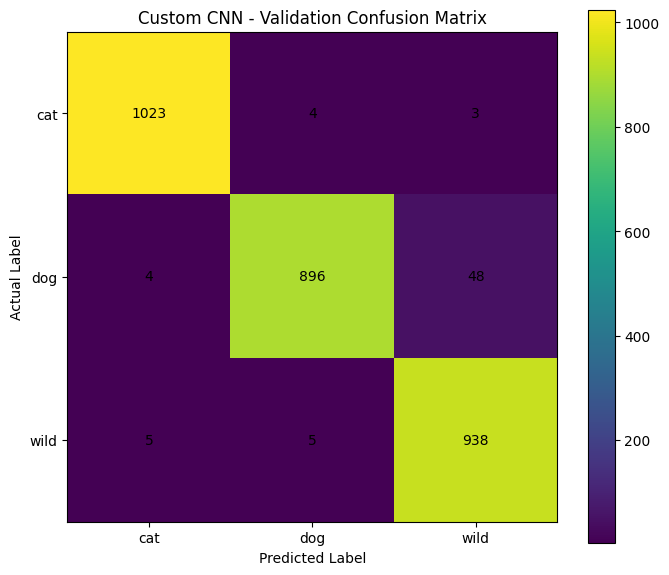


VALIDATION PERFORMANCE SUMMARY
Accuracy:       0.9764
Macro Precision:0.9766
Macro Recall:   0.9759
Macro F1:       0.9759

GPU batch-1 latency: 1.942 ms
GPU throughput:      515.00 images/sec

Saved:
 - validation_metrics.json
 - confusion_matrix.png


In [13]:
# ============================================================
# STEP 8: VALIDATION EVALUATION & PERFORMANCE ANALYSIS
# ============================================================

import json
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

from pathlib import Path

ARTIFACT_DIR = Path("/content/artifacts/custom_cnn")

# ------------------------------------------------------------
# 1. LOAD BEST CHECKPOINT
# ------------------------------------------------------------

checkpoint = torch.load(
    ARTIFACT_DIR / "best_model.pth",
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Evaluating checkpoint from epoch:", checkpoint["epoch"])

# ------------------------------------------------------------
# 2. VALIDATION PREDICTIONS
# ------------------------------------------------------------

all_predictions = []
all_targets = []
all_probabilities = []

model.eval()

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)

        probabilities = torch.softmax(outputs.float(), dim=1)
        predictions = probabilities.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(labels.numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

all_predictions = np.array(all_predictions)
all_targets = np.array(all_targets)
all_probabilities = np.array(all_probabilities)

# ------------------------------------------------------------
# 3. CLASSIFICATION METRICS
# ------------------------------------------------------------

class_names = [
    IDX_TO_CLASS[i]
    for i in range(len(IDX_TO_CLASS))
]

accuracy = accuracy_score(
    all_targets,
    all_predictions
)

precision, recall, macro_f1, _ = (
    precision_recall_fscore_support(
        all_targets,
        all_predictions,
        average="macro",
        zero_division=0
    )
)

report = classification_report(
    all_targets,
    all_predictions,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        all_targets,
        all_predictions,
        target_names=class_names,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 4. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    all_targets,
    all_predictions
)

plt.figure(figsize=(7, 6))

plt.imshow(cm, interpolation="nearest")
plt.title("Custom CNN - Validation Confusion Matrix")
plt.colorbar()

plt.xticks(range(3), class_names)
plt.yticks(range(3), class_names)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    ARTIFACT_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. INFERENCE LATENCY BENCHMARK
# ------------------------------------------------------------

dummy_input = torch.randn(
    1, 3, IMAGE_SIZE, IMAGE_SIZE,
    device=DEVICE
)

# Warmup
with torch.inference_mode():
    for _ in range(30):
        _ = model(dummy_input)

torch.cuda.synchronize()

iterations = 200

start_time = time.perf_counter()

with torch.inference_mode():
    for _ in range(iterations):
        _ = model(dummy_input)

torch.cuda.synchronize()

total_time = time.perf_counter() - start_time

avg_latency_ms = (
    total_time / iterations
) * 1000

throughput = 1000 / avg_latency_ms

# ------------------------------------------------------------
# 6. SAVE METRICS
# ------------------------------------------------------------

metrics = {
    "model": "CustomCNN",
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "validation_accuracy": float(accuracy),
    "validation_macro_precision": float(precision),
    "validation_macro_recall": float(recall),
    "validation_macro_f1": float(macro_f1),
    "class_metrics": report,
    "confusion_matrix": cm.tolist(),
    "inference_device": str(DEVICE),
    "batch_size": 1,
    "average_gpu_latency_ms": float(avg_latency_ms),
    "gpu_throughput_images_per_second": float(throughput)
}

with open(ARTIFACT_DIR / "validation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("VALIDATION PERFORMANCE SUMMARY")
print("=" * 55)

print(f"Accuracy:       {accuracy:.4f}")
print(f"Macro Precision:{precision:.4f}")
print(f"Macro Recall:   {recall:.4f}")
print(f"Macro F1:       {macro_f1:.4f}")

print(f"\nGPU batch-1 latency: {avg_latency_ms:.3f} ms")
print(f"GPU throughput:      {throughput:.2f} images/sec")

print("\nSaved:")
print(" - validation_metrics.json")
print(" - confusion_matrix.png")

FINAL TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

         cat       0.98      1.00      0.99       500
         dog       1.00      0.93      0.96       500
        wild       0.94      0.98      0.96       500

    accuracy                           0.97      1500
   macro avg       0.97      0.97      0.97      1500
weighted avg       0.97      0.97      0.97      1500


FINAL TEST PERFORMANCE
Accuracy:        0.9700
Macro Precision: 0.9710
Macro Recall:    0.9700
Macro F1:        0.9700


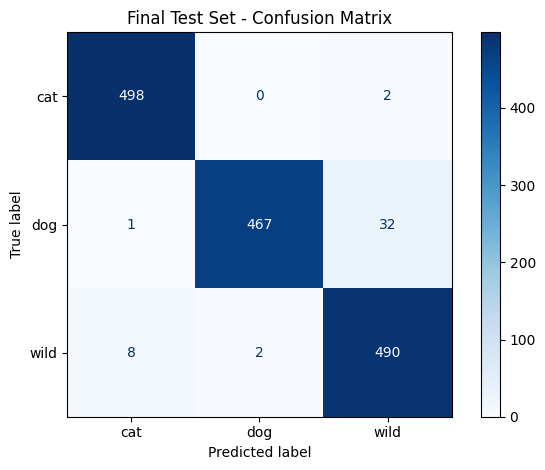


Saved test_metrics.json and test_confusion_matrix.png


In [14]:
import json
import time
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

# Final test metrics
accuracy = accuracy_score(all_targets, all_preds)
precision = precision_score(
    all_targets, all_preds, average="macro", zero_division=0
)
recall = recall_score(
    all_targets, all_preds, average="macro", zero_division=0
)
macro_f1 = f1_score(
    all_targets, all_preds, average="macro", zero_division=0
)

report = classification_report(
    all_targets,
    all_preds,
    target_names=["cat", "dog", "wild"],
    output_dict=True,
    zero_division=0
)

print("FINAL TEST CLASSIFICATION REPORT")
print(classification_report(
    all_targets,
    all_preds,
    target_names=["cat", "dog", "wild"],
    zero_division=0
))

print("\nFINAL TEST PERFORMANCE")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1:        {macro_f1:.4f}")

# Save metrics
test_metrics = {
    "accuracy": accuracy,
    "macro_precision": precision,
    "macro_recall": recall,
    "macro_f1": macro_f1,
    "classification_report": report,
    "test_samples": len(all_targets),
    "evaluated_checkpoint_epoch": 11
}

with open(ARTIFACT_DIR / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=4)

# Save confusion matrix
cm = confusion_matrix(all_targets, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["cat", "dog", "wild"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Final Test Set - Confusion Matrix")
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "test_confusion_matrix.png", dpi=200)
plt.show()

print("\nSaved test_metrics.json and test_confusion_matrix.png")

In [15]:
from pathlib import Path
import json
import shutil
import zipfile
import torch

ARTIFACT_DIR = Path("/content/artifacts/custom_cnn")
EXPORT_DIR = Path("/content/humanli_model_export")

EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# The best checkpoint is already loaded in `model` from evaluation.
model = model.cpu()
model.eval()

# Save inference-only weights (no optimizer state).
torch.save(
    model.state_dict(),
    EXPORT_DIR / "custom_cnn_state_dict.pth"
)

# Model configuration
model_config = {
    "architecture": "CustomCNN",
    "input_channels": 3,
    "num_classes": 3,
    "image_size": 224,
    "parameters": 1206499
}

# Class mapping
class_mapping = {
    "cat": 0,
    "dog": 1,
    "wild": 2
}

# Must match the evaluation preprocessing used during training.
preprocessing_config = {
    "image_size": 224,
    "color_mode": "RGB",
    "resize": [224, 224],
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    }
}

for filename, data in [
    ("model_config.json", model_config),
    ("class_mapping.json", class_mapping),
    ("preprocessing_config.json", preprocessing_config)
]:
    with open(EXPORT_DIR / filename, "w") as f:
        json.dump(data, f, indent=4)

# Copy evaluation evidence and training history.
optional_files = [
    "validation_metrics.json",
    "test_metrics.json",
    "training_history.csv",
    "confusion_matrix.png",
    "test_confusion_matrix.png"
]

for filename in optional_files:
    source = ARTIFACT_DIR / filename
    if source.exists():
        shutil.copy2(source, EXPORT_DIR / filename)

# Package artifacts.
zip_path = Path("/content/humanli_model_artifacts.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in EXPORT_DIR.iterdir():
        if file.is_file():
            z.write(file, arcname=file.name)

print("Export completed:")
for file in EXPORT_DIR.iterdir():
    if file.is_file():
        print(f"{file.name}: {file.stat().st_size / 1024:.1f} KB")

print(f"\nZIP: {zip_path}")

Export completed:
model_config.json: 0.1 KB
validation_metrics.json: 1.6 KB
preprocessing_config.json: 0.3 KB
training_history.csv: 2.0 KB
test_confusion_matrix.png: 50.8 KB
confusion_matrix.png: 59.8 KB
class_mapping.json: 0.0 KB
custom_cnn_state_dict.pth: 4738.7 KB
test_metrics.json: 1.1 KB

ZIP: /content/humanli_model_artifacts.zip


In [16]:
from google.colab import files
files.download("/content/humanli_model_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
from pathlib import Path
import shutil
import zipfile

source = Path("/content/artifacts/custom_cnn")
destination = Path("/content/humanli_additional_artifacts")

destination.mkdir(exist_ok=True)

for name in [
    "best_model.pth",
    "latest_checkpoint.pth",
]:
    if (source / name).exists():
        shutil.copy2(source / name, destination / name)

manifest_source = Path(
    "/content/humanli-cnn-classification/data/manifests"
)
manifest_destination = destination / "data_manifests"
manifest_destination.mkdir(exist_ok=True)

for name in ["train.csv", "validation.csv", "test.csv"]:
    if (manifest_source / name).exists():
        shutil.copy2(
            manifest_source / name,
            manifest_destination / name
        )

with zipfile.ZipFile(
    "/content/humanli_additional_artifacts.zip", "w",
    zipfile.ZIP_DEFLATED
) as archive:
    for file in destination.rglob("*"):
        if file.is_file():
            archive.write(file, file.relative_to(destination))

print("Additional artifact archive created.")
print("Files:", [str(p.relative_to(destination))
                 for p in destination.rglob("*") if p.is_file()])

Additional artifact archive created.
Files: ['latest_checkpoint.pth', 'best_model.pth', 'data_manifests/validation.csv', 'data_manifests/test.csv', 'data_manifests/train.csv']


In [18]:
files.download("/content/humanli_additional_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
%pip install -q onnx onnxscript

In [21]:
import json
import sys
import subprocess
import zipfile
from pathlib import Path
from datetime import datetime, timezone

import torch
import torch.nn as nn

# Install ONNX validation package only if missing
try:
    import onnx
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "onnx"
    ])
    import onnx

# Paths
ARTIFACT_DIR = Path("/content/artifacts/custom_cnn")
ONNX_PATH = ARTIFACT_DIR / "custom_cnn.onnx"
ZIP_PATH = Path("/content/humanli_model_artifacts.zip")

# Use the already-trained, evaluated model
assert "model" in globals(), "Trained model is not available."

model = model.cpu()
model.eval()

# Check output shape before export
dummy_input = torch.randn(1, 3, 224, 224)

with torch.no_grad():
    output = model(dummy_input)

assert output.shape == (1, 3), f"Unexpected output shape: {output.shape}"

# Export ONNX
torch.onnx.export(
    model,
    dummy_input,
    str(ONNX_PATH),
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["images"],
    output_names=["logits"],
    dynamic_axes={
        "images": {0: "batch_size"},
        "logits": {0: "batch_size"}
    }
)

# Validate ONNX graph
onnx_model = onnx.load(str(ONNX_PATH))
onnx.checker.check_model(onnx_model)

# Save export metadata
onnx_metadata = {
    "format": "ONNX",
    "file": "custom_cnn.onnx",
    "opset_version": 17,
    "input_name": "images",
    "input_shape": ["batch_size", 3, 224, 224],
    "output_name": "logits",
    "output_shape": ["batch_size", 3],
    "architecture": "CustomCNN",
    "class_mapping": {
        "cat": 0,
        "dog": 1,
        "wild": 2
    },
    "source_weights": "custom_cnn_state_dict.pth",
    "exported_at_utc": datetime.now(timezone.utc).isoformat(),
    "pytorch_version": torch.__version__,
    "onnx_version": onnx.__version__
}

metadata_path = ARTIFACT_DIR / "onnx_export_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(onnx_metadata, f, indent=4)

# Update existing artifact ZIP without duplicating old entries
assert ZIP_PATH.exists(), "Original artifact ZIP not found."

TEMP_ZIP = ZIP_PATH.with_name("humanli_model_artifacts_updated.zip")

with zipfile.ZipFile(ZIP_PATH, "r") as old_zip:
    with zipfile.ZipFile(TEMP_ZIP, "w", zipfile.ZIP_DEFLATED) as new_zip:

        for item in old_zip.infolist():
            if item.filename not in {
                "custom_cnn.onnx",
                "onnx_export_metadata.json"
            }:
                new_zip.writestr(item, old_zip.read(item.filename))

        new_zip.write(ONNX_PATH, "custom_cnn.onnx")
        new_zip.write(metadata_path, "onnx_export_metadata.json")

# Verify updated ZIP
with zipfile.ZipFile(TEMP_ZIP, "r") as archive:
    assert archive.testzip() is None
    assert "custom_cnn.onnx" in archive.namelist()
    assert "onnx_export_metadata.json" in archive.namelist()

TEMP_ZIP.replace(ZIP_PATH)

print("ONNX EXPORT SUCCESSFUL")
print("ONNX version:", onnx.__version__)
print("PyTorch version:", torch.__version__)
print("Opset:", 17)
print("Input:", "[batch_size, 3, 224, 224]")
print("Output:", "[batch_size, 3]")
print("ONNX file size:", round(ONNX_PATH.stat().st_size / (1024 * 1024), 2), "MB")
print("ONNX graph validation: PASSED")
print("Updated ZIP:", ZIP_PATH)

/tmp/ipykernel_5605/1604104668.py:40: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1115 07:17:50.192000 5605 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `CustomCNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `CustomCNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX EXPORT SUCCESSFUL
ONNX version: 1.23.2
PyTorch version: 2.14.1+cu130
Opset: 17
Input: [batch_size, 3, 224, 224]
Output: [batch_size, 3]
ONNX file size: 0.05 MB
ONNX graph validation: PASSED
Updated ZIP: /content/humanli_model_artifacts.zip


In [22]:
from pathlib import Path
import onnx
import json

onnx_path = Path("/content/artifacts/custom_cnn/custom_cnn.onnx")
weights_path = Path("/content/artifacts/custom_cnn/custom_cnn_state_dict.pth")

onnx_model = onnx.load(str(onnx_path))

print("ONNX FILE:", round(onnx_path.stat().st_size / 1024, 2), "KB")
print("PYTORCH FILE:", round(weights_path.stat().st_size / 1024, 2), "KB")

print("\nOPSET IMPORTS:")
for opset in onnx_model.opset_import:
    print(opset.domain or "ai.onnx", opset.version)

print("\nGRAPH INPUTS:")
for item in onnx_model.graph.input:
    print(item.name)

print("\nGRAPH OUTPUTS:")
for item in onnx_model.graph.output:
    print(item.name)

print("\nINITIALIZERS:", len(onnx_model.graph.initializer))

initializer_bytes = sum(
    len(tensor.raw_data)
    for tensor in onnx_model.graph.initializer
)

print("INITIALIZER RAW DATA:", round(initializer_bytes / 1024 / 1024, 3), "MB")

external_data = [
    tensor.name
    for tensor in onnx_model.graph.initializer
    if tensor.data_location == onnx.TensorProto.EXTERNAL
]

print("EXTERNAL WEIGHT TENSORS:", len(external_data))

onnx.checker.check_model(onnx_model)
print("\nONNX GRAPH CHECK: PASSED")

ONNX FILE: 47.49 KB


FileNotFoundError: [Errno 2] No such file or directory: '/content/artifacts/custom_cnn/custom_cnn_state_dict.pth'

In [23]:
from pathlib import Path

for filename in ["custom_cnn.onnx", "custom_cnn_state_dict.pth"]:
    print(f"\nSearching for {filename}")

    matches = list(Path("/content").rglob(filename))

    if matches:
        for path in matches:
            print(path, "|", round(path.stat().st_size / 1024, 2), "KB")
    else:
        print("NOT FOUND")


Searching for custom_cnn.onnx
/content/artifacts/custom_cnn/custom_cnn.onnx | 47.49 KB

Searching for custom_cnn_state_dict.pth
/content/humanli_model_export/custom_cnn_state_dict.pth | 4738.74 KB


In [24]:
import onnx

onnx_path = "/content/artifacts/custom_cnn/custom_cnn.onnx"

onnx_model = onnx.load(onnx_path)

print("ONNX size:", len(open(onnx_path, "rb").read()) / 1024, "KB")

print("\nOpset:")
for op in onnx_model.opset_import:
    print(op.domain or "ai.onnx", op.version)

print("\nInputs:")
for x in onnx_model.graph.input:
    print(x.name)

print("\nOutputs:")
for x in onnx_model.graph.output:
    print(x.name)

print("\nInitializer count:", len(onnx_model.graph.initializer))

weight_bytes = sum(
    len(t.raw_data)
    for t in onnx_model.graph.initializer
)

print("Weight data:", round(weight_bytes / 1024 / 1024, 3), "MB")

onnx.checker.check_model(onnx_model)
print("\nGraph validation: PASSED")

ONNX size: 47.4931640625 KB

Opset:
ai.onnx 18

Inputs:
images

Outputs:
logits

Initializer count: 22
Weight data: 4.599 MB

Graph validation: PASSED


In [25]:
import torch
import numpy as np
import onnxruntime as ort

# Load the trained PyTorch weights
weights_path = "/content/humanli_model_export/custom_cnn_state_dict.pth"

state_dict = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict)
model.cpu()
model.eval()

# ONNX Runtime
session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

# Same input to both models
test_input = torch.randn(2, 3, 224, 224)

with torch.no_grad():
    pytorch_output = model(test_input).numpy()

onnx_output = session.run(
    ["logits"],
    {"images": test_input.numpy()}
)[0]

difference = np.max(np.abs(pytorch_output - onnx_output))

print("PyTorch shape:", pytorch_output.shape)
print("ONNX shape:", onnx_output.shape)
print("Maximum output difference:", difference)

print("PyTorch predictions:", pytorch_output.argmax(axis=1))
print("ONNX predictions:", onnx_output.argmax(axis=1))

assert np.allclose(
    pytorch_output,
    onnx_output,
    atol=1e-3,
    rtol=1e-3
), "Output mismatch!"

print("\nONNX AND PYTORCH MATCH!")

ModuleNotFoundError: No module named 'onnxruntime'

In [26]:
%pip install -q onnxruntime

In [27]:
import torch
import numpy as np
import onnxruntime as ort

onnx_path = "/content/artifacts/custom_cnn/custom_cnn.onnx"
weights_path = "/content/humanli_model_export/custom_cnn_state_dict.pth"

# Restore the exact trained weights
state_dict = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict)
model.eval()
model.cpu()

# ONNX CPU inference session
session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

# Test identical input
x = torch.randn(2, 3, 224, 224)

with torch.no_grad():
    pytorch_output = model(x).numpy()

onnx_output = session.run(
    ["logits"],
    {"images": x.numpy()}
)[0]

max_diff = np.max(np.abs(pytorch_output - onnx_output))

print("PyTorch output:", pytorch_output.shape)
print("ONNX output:", onnx_output.shape)
print("Maximum absolute difference:", max_diff)

print("PyTorch classes:", pytorch_output.argmax(axis=1))
print("ONNX classes:", onnx_output.argmax(axis=1))

assert np.allclose(pytorch_output, onnx_output, atol=1e-3, rtol=1e-3)

print("SUCCESS: Both models produce matching outputs.")

PyTorch output: (2, 3)
ONNX output: (2, 3)
Maximum absolute difference: 2.3841858e-06
PyTorch classes: [2 2]
ONNX classes: [2 2]
SUCCESS: Both models produce matching outputs.


In [28]:
from pathlib import Path
import shutil
import json
import hashlib
import zipfile
import onnx
from datetime import datetime, timezone

# --------------------------------------------------
# SOURCE PATHS
# --------------------------------------------------
ARTIFACTS = Path("/content/artifacts/custom_cnn")
EXPORT = Path("/content/humanli_model_export")
ONNX_DIR = ARTIFACTS
MANIFESTS = Path(
    "/content/humanli-cnn-classification/data/manifests"
)

FINAL_DIR = Path("/content/humanli_complete_backup")
FINAL_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. COPY PYTORCH INFERENCE WEIGHTS
# --------------------------------------------------
pytorch_weights = EXPORT / "custom_cnn_state_dict.pth"

assert pytorch_weights.exists(), "PyTorch weights missing!"

shutil.copy2(
    pytorch_weights,
    FINAL_DIR / "custom_cnn_state_dict.pth"
)

# --------------------------------------------------
# 2. COPY ONNX MODEL AND EXTERNAL DATA
# --------------------------------------------------
onnx_path = ONNX_DIR / "custom_cnn.onnx"

assert onnx_path.exists(), "ONNX model missing!"

shutil.copy2(onnx_path, FINAL_DIR / "custom_cnn.onnx")

# Inspect external tensor references without loading their data
onnx_metadata_model = onnx.load(
    str(onnx_path),
    load_external_data=False
)

external_locations = set()

for tensor in onnx_metadata_model.graph.initializer:
    if tensor.data_location == onnx.TensorProto.EXTERNAL:
        metadata = {
            item.key: item.value
            for item in tensor.external_data
        }
        if "location" in metadata:
            external_locations.add(metadata["location"])

# Preserve every referenced sidecar file
for location in external_locations:
    source = ONNX_DIR / location
    assert source.exists(), f"Missing ONNX external data: {source}"

    destination = FINAL_DIR / location
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

print("ONNX external data files:", list(external_locations))

# --------------------------------------------------
# 3. COPY TRAINING CHECKPOINTS IF AVAILABLE
# --------------------------------------------------
for filename in ["best_model.pth", "latest_checkpoint.pth"]:
    source = ARTIFACTS / filename

    if source.exists():
        shutil.copy2(source, FINAL_DIR / filename)

# --------------------------------------------------
# 4. COPY METRICS, PLOTS AND HISTORY
# --------------------------------------------------
evidence_files = [
    "validation_metrics.json",
    "test_metrics.json",
    "training_history.csv",
    "confusion_matrix.png",
    "test_confusion_matrix.png"
]

for filename in evidence_files:
    source = ARTIFACTS / filename

    if source.exists():
        shutil.copy2(source, FINAL_DIR / filename)

# --------------------------------------------------
# 5. COPY DATASET MANIFESTS
# --------------------------------------------------
manifest_destination = FINAL_DIR / "data_manifests"
manifest_destination.mkdir(exist_ok=True)

for filename in ["train.csv", "validation.csv", "test.csv"]:
    source = MANIFESTS / filename

    if source.exists():
        shutil.copy2(source, manifest_destination / filename)

# --------------------------------------------------
# 6. COPY CONFIGURATION FILES
# --------------------------------------------------
config_files = [
    "model_config.json",
    "class_mapping.json",
    "preprocessing_config.json",
    "onnx_export_metadata.json"
]

for filename in config_files:
    source = EXPORT / filename

    if source.exists():
        shutil.copy2(source, FINAL_DIR / filename)

    elif (ARTIFACTS / filename).exists():
        shutil.copy2(
            ARTIFACTS / filename,
            FINAL_DIR / filename
        )

# --------------------------------------------------
# 7. ADD REPRODUCIBILITY METADATA
# --------------------------------------------------
backup_metadata = {
    "project": "Humanli CNN Image Classification",
    "architecture": "CustomCNN",
    "classes": ["cat", "dog", "wild"],
    "input_shape": [3, 224, 224],
    "best_epoch": 11,
    "final_test_accuracy": 0.97,
    "final_test_macro_f1": 0.97,
    "pytorch_weights": "custom_cnn_state_dict.pth",
    "onnx_model": "custom_cnn.onnx",
    "onnx_opset": 18,
    "onnx_external_data": list(external_locations),
    "exported_at_utc": datetime.now(timezone.utc).isoformat()
}

(FINAL_DIR / "backup_metadata.json").write_text(
    json.dumps(backup_metadata, indent=4)
)

# --------------------------------------------------
# 8. GENERATE CHECKSUMS
# --------------------------------------------------
checksum_lines = []

for file in sorted(FINAL_DIR.rglob("*")):
    if file.is_file() and file.name != "SHA256SUMS.txt":
        digest = hashlib.sha256(file.read_bytes()).hexdigest()
        checksum_lines.append(
            f"{digest}  {file.relative_to(FINAL_DIR)}"
        )

(FINAL_DIR / "SHA256SUMS.txt").write_text(
    "\n".join(checksum_lines)
)

# --------------------------------------------------
# 9. CREATE FINAL ARCHIVE
# --------------------------------------------------
ZIP_PATH = Path("/content/humanli_complete_backup.zip")

with zipfile.ZipFile(
    ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as archive:
    for file in FINAL_DIR.rglob("*"):
        if file.is_file():
            archive.write(file, file.relative_to(FINAL_DIR))

# --------------------------------------------------
# 10. VERIFY ARCHIVE INTEGRITY
# --------------------------------------------------
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    assert archive.testzip() is None

    archived_files = set(archive.namelist())

    assert "custom_cnn_state_dict.pth" in archived_files
    assert "custom_cnn.onnx" in archived_files

    for location in external_locations:
        assert location in archived_files, (
            f"ONNX external data missing from ZIP: {location}"
        )

print("\n" + "=" * 60)
print("COMPLETE BACKUP CREATED AND VERIFIED")
print("=" * 60)

for file in sorted(FINAL_DIR.rglob("*")):
    if file.is_file():
        print(
            f"{file.relative_to(FINAL_DIR)} | "
            f"{file.stat().st_size / 1024:.2f} KB"
        )

print("\nArchive size:",
      round(ZIP_PATH.stat().st_size / (1024 * 1024), 2), "MB")

print("Archive integrity: PASSED")
print("PyTorch weights: VERIFIED PRESENT")
print("ONNX model: VERIFIED PRESENT")
print("ONNX external data: VERIFIED PRESENT")

ONNX external data files: ['custom_cnn.onnx.data']

COMPLETE BACKUP CREATED AND VERIFIED
SHA256SUMS.txt | 1.55 KB
backup_metadata.json | 0.53 KB
best_model.pth | 14189.40 KB
class_mapping.json | 0.04 KB
confusion_matrix.png | 59.76 KB
custom_cnn.onnx | 47.49 KB
custom_cnn.onnx.data | 4708.38 KB
custom_cnn_state_dict.pth | 4738.74 KB
data_manifests/test.csv | 91.71 KB
data_manifests/train.csv | 738.38 KB
data_manifests/validation.csv | 184.64 KB
latest_checkpoint.pth | 14190.37 KB
model_config.json | 0.13 KB
onnx_export_metadata.json | 0.57 KB
preprocessing_config.json | 0.29 KB
test_confusion_matrix.png | 50.83 KB
test_metrics.json | 1.14 KB
training_history.csv | 2.01 KB
validation_metrics.json | 1.64 KB

Archive size: 34.1 MB
Archive integrity: PASSED
PyTorch weights: VERIFIED PRESENT
ONNX model: VERIFIED PRESENT
ONNX external data: VERIFIED PRESENT


In [29]:
from google.colab import files

files.download("/content/humanli_complete_backup.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>